# Recovering a latent signal with time-series dimension reduction

This notebook reproduces the numerical experiments in

> K. S. Owens and B. D. Fulcher, *Time-Series Dimension Reduction: A Comprehensive Review and Conceptual Unification of Algorithms* (preprint: TechRxiv, 2025).

using the [`tsdr`](https://github.com/kieranowens/tsdr) package (version 0.11). Each experiment hides a one-dimensional latent signal $z_t$ among $D-1$ noise sources, mixes them with a random orthogonal matrix, and asks each of the 30 `tsdr` methods and eight general-purpose dimension-reduction (GDR) methods for a single component $y_t$. Performance is the squared correlation $R^2 = \mathrm{corr}(y, z)^2$ (which ignores the arbitrary sign and scale of $y$).

| Section | Experiment | Figure |
|---|---|---|
| 1 | Sinusoid in isotropic noise of increasing variance, with full-rank or low-rank noise | Fig. 4a–b |
| 2 | Sinusoid in noise with one dominant eigenvalue $\lambda_1$ and a noise floor $\epsilon$ | Fig. 4c–d |
| 3 | AR(1), heteroskedastic and logistic-map signals in noise (PCA, SFA, ASSA, PrCA) | Fig. 4e |
| S1 | As 1 with low-rank noise, for noise variances $\sigma^2 = 10^{-2}, 10^{-1}, \ldots, 10^{14}$ | Fig. S1 |
| S2 | As 2, for every method (no new runs) | Fig. S2 |
| S3 | As 1, scoring the best of three components | Fig. S3 |

Figure 4 is in the main text and Figs S1–S3 in the supplement. Results are saved to `results/` and loaded on later runs, so the figures can be redrawn without re-running the experiments (set `OVERWRITE = True` to re-run). The full experiments take many hours, mostly in t-SNE, the autoencoder and the EM-fitted LDS and DFA; set `QUICK = True` to check that everything runs in a few minutes.

## Setup

In [1]:
import json
import shutil
import time
from pathlib import Path

import numpy as np
import scipy.stats
import matplotlib as mpl
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.decomposition import PCA, FastICA, FactorAnalysis
from sklearn.manifold import TSNE, Isomap, SpectralEmbedding
from sklearn.neural_network import MLPRegressor
from umap import UMAP

from tsdr.slowness import SFA, BioSFA, ISFA, SICA
from tsdr.autocorrelation import TICA, TMCA, TCCA_Stiefel, CSA, sPCA_dwt
from tsdr.predictability import TLPC, PrCA, DiCCA, ForeCA, PFA, PTS, DCA
from tsdr.determinism import DMD, DyCA
from tsdr.nonstationarity import ASSA, SSAsir, SSAsave, SSAcor, WaSSAf, WaSSAr, BSSnonstat
from tsdr.diffusion import DMcov, DIG, NLSA
from tsdr.latentvariable import LDS, DFA

/opt/anaconda3/envs/tsdr_paper/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#%pip install --only-binary=:all: umap-learn

In [3]:

SEED = 1           # master random seed (each experiment derives its own seeds from it)
QUICK = False      # True: few iterations on coarse grids, to check the notebook runs (about an hour)
OVERWRITE = False   # True: re-run experiments even if saved results exist (set back to False after the clean run)
N_JOBS = -1        # parallel workers for the experiment loops (-1: all cores)

RESULTS_DIR = Path('results_quick' if QUICK else 'results')
FIGURES_DIR = Path('figures_quick' if QUICK else 'figures')
RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

def setting(full, quick):
    # experiment setting for the full run, or for a quick check
    return quick if QUICK else full

# use LaTeX for figure text if it is installed
if shutil.which('latex'):
    mpl.rcParams.update({'text.usetex': True, 'font.family': 'serif',
                         'font.serif': ['Computer Modern']})

## Methods

All 30 `tsdr` methods are compared with eight general-purpose (static) dimension reduction methods, PCA, ICA, factor analysis (FA), t-SNE, Isomap, UMAP, Laplacian eigenmaps (LapEig) and an autoencoder (AE), and a supervised *oracle* (the linear regression of $z$ on the data, which is the best any linear method can do). Each entry below gives a method's family, which sets its colour in the figures, and a function that constructs it with `n` components. Settings other than the defaults are noted in the table; stochastic methods are seeded for reproducibility.

ICA estimates all components with FastICA and keeps the most non-Gaussian (largest absolute excess kurtosis): scikit-learn's `FastICA(n_components=n)` would instead first reduce the data to its `n` principal components, and so behave like PCA.

The diffusion methods return different numbers of time points: DMcov and DIG return one value per sliding window, which is compared with the mean of $z$ in that window, and NLSA returns one value per time-lagged embedding vector, which is compared with $z$ from time $q$ onwards.

In [4]:
FAMILY_COLOURS = {'general':         '#666666',
                  'slowness':        '#C23B23',
                  'autocorrelation': '#c8760b',
                  'predictability':  '#d3c01a',
                  'determinism':     '#02902d',
                  'nonstationarity': '#3a7696',
                  'diffusion':       '#6431b2',
                  'latent variable': '#e441a8',
                  'oracle':          'black'}

# sliding windows for DMcov and DIG, and the embedding window for NLSA
WINDOW, STEP = 100, 10
NLSA_LAGS = 10


class Autoencoder:
    # A fully connected autoencoder with a bottleneck of n units, trained to
    # reconstruct X; MLPRegressor applies ReLU to every hidden layer (including
    # the bottleneck), and the components are the bottleneck pre-activations.

    def __init__(self, n_components=1, hidden=10, random_state=0):
        self.n_components = n_components
        self.mlp = MLPRegressor(hidden_layer_sizes=(hidden, hidden, n_components, hidden, hidden),
                                alpha=1e-15, max_iter=10000, random_state=random_state)

    def fit_transform(self, X):
        self.mlp.fit(X, X)
        # encoder: two ReLU layers, then the bottleneck pre-activation
        h = X
        for W, b in zip(self.mlp.coefs_[:2], self.mlp.intercepts_[:2]):
            h = np.maximum(0, h @ W + b)
        return h @ self.mlp.coefs_[2] + self.mlp.intercepts_[2]


class ICA:
    # FastICA estimating all components, keeping the n most non-Gaussian
    # (largest |excess kurtosis|); FastICA(n_components=n) would instead first
    # reduce the data to its n principal components, and so behave like PCA

    def __init__(self, n_components=1, random_state=0):
        self.n_components = n_components
        self.random_state = random_state

    def fit_transform(self, X):
        Y = FastICA(n_components=X.shape[1],
                    random_state=self.random_state).fit_transform(X)
        order = np.argsort(-np.abs(scipy.stats.kurtosis(Y)))
        return Y[:, order[:self.n_components]]


METHODS = {
    # general-purpose dimension reduction
    'PCA':        ('general', lambda n: PCA(n_components=n)),
    'ICA':        ('general', lambda n: ICA(n_components=n)),
    'FA':         ('general', lambda n: FactorAnalysis(n_components=n, random_state=0)),
    'tSNE':       ('general', lambda n: TSNE(n_components=n, random_state=0)),
    'Isomap':     ('general', lambda n: Isomap(n_components=n)),
    'UMAP':       ('general', lambda n: UMAP(n_components=n, random_state=0)),
    'LapEig':     ('general', lambda n: SpectralEmbedding(n_components=n, random_state=0)),
    'AE':         ('general', lambda n: Autoencoder(n_components=n)),
    # slowness
    'SFA':        ('slowness', lambda n: SFA(n_components=n)),
    'BioSFA':     ('slowness', lambda n: BioSFA(n_components=n, n_iters=1000, lr=0.1, random_state=0)),
    'ISFA':       ('slowness', lambda n: ISFA(n_components=n, random_state=0)),
    'SICA':       ('slowness', lambda n: SICA(n_components=n, random_state=0)),
    # autocorrelation
    'TICA':       ('autocorrelation', lambda n: TICA(n_components=n)),
    'TMCA':       ('autocorrelation', lambda n: TMCA(n_components=n)),
    'TCCA':       ('autocorrelation', lambda n: TCCA_Stiefel(n_components=n)),
    'CSA':        ('autocorrelation', lambda n: CSA(n_components=n, lag=10)),
    'sPCA':       ('autocorrelation', lambda n: sPCA_dwt(n_components=n)),
    # predictability
    'TLPC':       ('predictability', lambda n: TLPC(n_components=n)),
    'PrCA':       ('predictability', lambda n: PrCA(n_components=n, p=5, model='linear_reg')),
    'DiCCA':      ('predictability', lambda n: DiCCA(n_components=n, s=5)),
    'ForeCA':     ('predictability', lambda n: ForeCA(n_components=n, random_state=0)),
    'PFA':        ('predictability', lambda n: PFA(n_components=n)),
    'PTS':        ('predictability', lambda n: PTS(n_components=n, M=2)),
    'DCA':        ('predictability', lambda n: DCA(n_components=n, random_state=0)),
    # determinism
    'DMD':        ('determinism', lambda n: DMD(n_components=n)),
    'DyCA':       ('determinism', lambda n: DyCA(n_components=n)),
    # nonstationarity
    'ASSA':       ('nonstationarity', lambda n: ASSA(n_components=n)),
    'SSAsir':     ('nonstationarity', lambda n: SSAsir(n_components=n)),
    'SSAsave':    ('nonstationarity', lambda n: SSAsave(n_components=n)),
    'SSAcor':     ('nonstationarity', lambda n: SSAcor(n_components=n)),
    'WaSSAf':     ('nonstationarity', lambda n: WaSSAf(n_components=n)),
    'WaSSAr':     ('nonstationarity', lambda n: WaSSAr(n_components=n)),
    'BSSnonstat': ('nonstationarity', lambda n: BSSnonstat(n_components=n, lag=1, max_iters=10, random_state=0)),
    # diffusion
    'DMcov':      ('diffusion', lambda n: DMcov(WINDOW, STEP, n_components=n, distance='mean_mahalanobis', normalise=False)),
    'DIG':        ('diffusion', lambda n: DIG(WINDOW, STEP, n_components=n)),
    'NLSA':       ('diffusion', lambda n: NLSA(n_components=n, q=NLSA_LAGS)),
    # latent variable
    'LDS':        ('latent variable', lambda n: LDS(n_components=n, random_state=0)),
    'DFA':        ('latent variable', lambda n: DFA(n_components=n, random_state=0)),
    # supervised upper bound (fitted to the latent signal in score())
    'Oracle':     ('oracle', None),
}

METHOD_NAMES = list(METHODS)

def colour(name):
    return FAMILY_COLOURS[METHODS[name][0]]

print(f'{len(METHOD_NAMES)} methods:', ', '.join(METHOD_NAMES))

39 methods: PCA, ICA, FA, tSNE, Isomap, UMAP, LapEig, AE, SFA, BioSFA, ISFA, SICA, TICA, TMCA, TCCA, CSA, sPCA, TLPC, PrCA, DiCCA, ForeCA, PFA, PTS, DCA, DMD, DyCA, ASSA, SSAsir, SSAsave, SSAcor, WaSSAf, WaSSAr, BSSnonstat, DMcov, DIG, NLSA, LDS, DFA, Oracle


### Scoring a method

`score` fits a method and returns the largest $R^2$ between any of its components and the latent signal (aligned to the method's output, as described above). A method that fails to fit scores zero, and the failure is reported.

In [5]:
def r2(y, z):
    # squared Pearson correlation
    return np.corrcoef(y, z)[0, 1] ** 2


def window_means(z, window=WINDOW, step=STEP):
    # mean of z in each of the sliding windows used by DMcov and DIG
    return np.array([z[i:i + window].mean() for i in range(0, len(z) - window + 1, step)])


def aligned_target(name, z):
    # the latent signal at the time points of the method's output
    if name in ('DMcov', 'DIG'):
        return window_means(z)
    if name == 'NLSA':
        return z[NLSA_LAGS:]
    return z


def score(name, X, z, n_components=1):
    # largest R^2 between a component of method `name` fitted to X and the latent signal z
    target = aligned_target(name, z)
    if name == 'Oracle':
        # least-squares fit of z on X (with intercept), solved directly so that
        # it remains accurate at extreme noise variances
        X1 = np.column_stack([X, np.ones(len(X))])
        Y = X1 @ np.linalg.lstsq(X1, z, rcond=None)[0]
    else:
        Y = METHODS[name][1](n_components).fit_transform(X)
    Y = np.real(Y).reshape(len(target), -1)
    values = [r2(y, target) for y in Y.T]
    if np.all(np.isnan(values)):
        raise FloatingPointError('all components are NaN')  # scored 0 by safe_score
    return np.nanmax(values)


def safe_score(name, X, z, n_components=1, failures=None):
    # score(), returning 0 (and recording the error) if the method fails
    try:
        return score(name, X, z, n_components)
    except Exception as e:
        if failures is not None:
            failures.append(f'{name}: {type(e).__name__}: {e}')
        return 0.0

## Data

The latent signal is hidden among $D - 1 = 9$ Gaussian noise sources with covariance $Q \Lambda Q^\top$, where $\Lambda = \mathrm{diag}(\lambda_1, \ldots, \lambda_{D-1})$ sets the noise eigenvalues and $Q$ is a random rotation. The $D$ sources are then mixed by a random rotation $A$, and $D - 1$ of the mixtures are observed:

$$X = [\, z, \; W \Lambda^{1/2} Q^\top \,] \, A_{:, 1:D-1},$$

where $W$ is a $T \times (D-1)$ matrix of standard normal draws. In each iteration of an experiment, $A$, $Q$ and $W$ are drawn once and reused across the experiment's grid, so that differences across the grid are due to the noise eigenvalues alone.

In [6]:
T_MAX = 1000       # time series length
D = 10             # number of sources (the latent signal and D - 1 noise sources)
N_CHANNELS = D - 1 # number of observed channels

# latent sinusoid (two periods, unit variance)
Z = np.sqrt(2) * np.sin(np.linspace(0, 4 * np.pi, T_MAX))


def random_mixing(rng):
    # random rotations A (sources) and Q (noise), and standard normal noise W
    A = scipy.stats.ortho_group.rvs(D, random_state=rng)
    Q = scipy.stats.ortho_group.rvs(D - 1, random_state=rng)
    W = rng.normal(size=(T_MAX, D - 1))
    return A, Q, W


def observe(z, noise_eigvals, A, Q, W):
    # mix the latent signal z with noise of the given eigenvalues (see above)
    noise = W @ np.diag(np.sqrt(noise_eigvals)) @ Q.T
    return np.column_stack([z, noise]) @ A[:, :N_CHANNELS]


FAILURES = []  # failed fits of the experiment currently being run (see load_or_run)


def package_versions():
    # versions of Python and of the packages that determine the results
    import platform
    from importlib.metadata import version
    packages = ['tsdr', 'numpy', 'scipy', 'scikit-learn', 'umap-learn', 'joblib']
    return {'python': platform.python_version(), **{p: version(p) for p in packages}}


def run_iterations(iteration, n_iters, experiment_id, **kwargs):
    # run iteration(seed, **kwargs) -> (R2, failures) in parallel, each with its
    # own seed derived from SEED, and stack the R2 arrays (first axis: iteration)
    seeds = np.random.SeedSequence([SEED, experiment_id]).spawn(n_iters)
    out = Parallel(n_jobs=N_JOBS, verbose=1)(delayed(iteration)(s, **kwargs) for s in seeds)
    failures = [f for _, fails in out for f in fails]
    FAILURES.extend(failures)
    if failures:
        names = [f.split(':')[0] for f in failures]
        print(f'{len(failures)} failed fits (scored 0):', {n: names.count(n) for n in dict.fromkeys(names)})
        print('e.g.', failures[0])
    return np.stack([R2 for R2, _ in out])


def load_or_run(name, run):
    # load saved results, or run the experiment (run() returns a dict of arrays) and save them
    path = RESULTS_DIR / f'{name}.npz'
    if path.exists() and not OVERWRITE:
        print(f'Loading {path}')
        return dict(np.load(path))
    start = time.time()
    FAILURES.clear()
    results = run()
    # record how many fits failed (scored 0) for each method, and the versions used
    names = [f.split(':')[0] for f in FAILURES]
    failure_counts = {n: names.count(n) for n in dict.fromkeys(names)}
    np.savez(path, **results, failure_counts=json.dumps(failure_counts),
             versions=json.dumps(package_versions()))
    print(f'Saved {path} ({(time.time() - start) / 60:.1f} min)')
    return results

## 1. Noise variance: full-rank and low-rank noise

The noise is isotropic with variance $\sigma^2$, $\Lambda = \sigma^2 I$ (*full-rank noise*), or the same with its last eigenvalue set to zero (*low-rank noise*). Low-rank noise leaves one direction of the observed space free of noise, so a method that finds it recovers the signal at any noise variance.

In [7]:
N_ITERS_NOISE = setting(20, 2)
NOISE_VARIANCES = 10.0 ** setting(np.arange(-1, 5.5, 0.5), np.arange(-1, 5.5, 1.5))
NOISE_TYPES = ['full-rank', 'low-rank']


def noise_iteration(seed, n_components=1):
    rng = np.random.default_rng(seed)
    A, Q, W = random_mixing(rng)
    R2 = np.zeros((len(NOISE_VARIANCES), len(NOISE_TYPES), len(METHOD_NAMES)))
    failures = []
    for i, variance in enumerate(NOISE_VARIANCES):
        for j, noise_type in enumerate(NOISE_TYPES):
            noise_eigvals = np.full(D - 1, variance)
            if noise_type == 'low-rank':
                noise_eigvals[-1] = 0.0
            X = observe(Z, noise_eigvals, A, Q, W)
            for k, name in enumerate(METHOD_NAMES):
                R2[i, j, k] = safe_score(name, X, Z, n_components, failures)
    return R2, failures


def run_noise_experiment(n_components=1, experiment_id=1):
    R2 = run_iterations(noise_iteration, N_ITERS_NOISE, experiment_id, n_components=n_components)
    return {'R2': R2,  # (iteration, noise variance, noise type, method)
            'noise_variances': NOISE_VARIANCES, 'noise_types': NOISE_TYPES, 'methods': METHOD_NAMES}


noise_results = load_or_run('noise', run_noise_experiment)

Loading results/noise.npz


## 2. Noise spectrum: dominant eigenvalue $\lambda_1$ and noise floor $\epsilon$

The noise has one dominant eigenvalue $\lambda_1$ and a floor $\epsilon \le \lambda_1$ for the other $D - 2$ eigenvalues, $\Lambda = \mathrm{diag}(\lambda_1, \epsilon, \ldots, \epsilon)$. Variance-based methods such as PCA fail once $\lambda_1$ exceeds the signal variance (one), whatever $\epsilon$; methods that use temporal structure instead depend mainly on $\epsilon$. ICA, although static, also depends mainly on $\epsilon$ here, because the sinusoid is the only non-Gaussian source. The main figure shows mean $R^2$ over the $(\log_{10} \lambda_1, \log_{10} \epsilon)$ grid for PCA, ICA and SFA (panel d), and S2 shows it for every method.

Grid points with $\epsilon > \lambda_1$ are not run (NaN).

In [8]:
N_ITERS_SPECTRUM = setting(20, 2)
LAMBDA1 = 10.0 ** np.linspace(-2, 2, setting(15, 5))
EPSILON = 10.0 ** np.linspace(-2, 2, setting(15, 5))


def spectrum_iteration(seed, lambda1, epsilon, n_floor):
    # the last n_floor noise eigenvalues are epsilon, the others lambda1
    rng = np.random.default_rng(seed)
    A, Q, W = random_mixing(rng)
    R2 = np.full((len(lambda1), len(epsilon), len(METHOD_NAMES)), np.nan)
    failures = []
    for i, lam1 in enumerate(lambda1):
        for j, eps in enumerate(epsilon):
            if eps > lam1:
                continue
            noise_eigvals = np.full(D - 1, lam1)
            noise_eigvals[D - 1 - n_floor:] = eps
            X = observe(Z, noise_eigvals, A, Q, W)
            for k, name in enumerate(METHOD_NAMES):
                R2[i, j, k] = safe_score(name, X, Z, failures=failures)
    return R2, failures


def run_spectrum_experiment(lambda1, epsilon, n_floor, n_iters, experiment_id):
    R2 = run_iterations(spectrum_iteration, n_iters, experiment_id, 
                        lambda1=lambda1, epsilon=epsilon, n_floor=n_floor)
    return {'R2': R2,  # (iteration, lambda1, epsilon, method)
            'lambda1': lambda1, 'epsilon': epsilon, 'n_floor': n_floor, 'methods': METHOD_NAMES}


spectrum_results = load_or_run('spectrum', lambda: run_spectrum_experiment(
    LAMBDA1, EPSILON, n_floor=D - 2, n_iters=N_ITERS_SPECTRUM, experiment_id=2))

Loading results/spectrum.npz


## 3. Signal processes

The sinusoid is replaced by a standardised stochastic signal whose temporal structure is set by a parameter in $[0, 1)$, and hidden in isotropic noise of variance $\sigma^2$:

* **AR(1)**: $z_t = \phi z_{t-1} + \eta_t$, with autocorrelation $\phi$, which slowness methods (SFA) exploit;
* **heteroskedastic Gaussian**: $z_t \sim \mathcal{N}(0, (1 + \alpha \sin(2\pi t / 500))^2)$, with non-stationarity $\alpha$, which ASSA exploits;
* **noisy logistic map**: $z_t = x_t + 0.5(1 - \beta)\eta_t$ with $x_{t+1} = 3.9\, x_t (1 - x_t)$, which is deterministic (predictable from its past, but uncorrelated) as $\beta \to 1$, and which PrCA exploits.

These experiments compare PCA with one representative method from each of these families (add names to `PROCESS_METHODS` to compare others).

In [9]:
N_ITERS_PROCESS = setting(20, 2)
PROCESS_PARAMS = setting(np.arange(0, 1, 0.05), np.arange(0, 1, 0.25))
PROCESS_NOISE_VARIANCES = 10.0 ** setting(np.arange(-1, 2.25, 0.25), np.arange(-1, 2.25, 1.0))
PROCESS_METHODS = ['PCA', 'SFA', 'ASSA', 'PrCA']


def standardise(x):
    return (x - x.mean()) / x.std()


def ar1(T, phi, rng):
    z = np.zeros(T)
    for t in range(1, T):
        z[t] = phi * z[t - 1] + rng.normal()
    return standardise(z)


def heteroskedastic(T, alpha, rng, period=500):
    sd = 1 + alpha * np.sin(2 * np.pi * np.arange(T) / period)
    return standardise(rng.normal(scale=sd))


def noisy_logistic(T, beta, rng, r=3.9, x0=0.2):
    x = np.zeros(T)
    x[0] = x0
    for t in range(T - 1):
        x[t + 1] = r * x[t] * (1 - x[t])
    return standardise(x + (1 - beta) * rng.normal(scale=0.5, size=T))


PROCESSES = {'ar1': ar1, 'heteroskedastic': heteroskedastic, 'logistic': noisy_logistic}


def process_iteration(seed, process):
    rng = np.random.default_rng(seed)
    A, Q, W = random_mixing(rng)
    # the same random draws generate the signal for every parameter value
    signal_seed = rng.integers(2**32)
    R2 = np.zeros((len(PROCESS_PARAMS), len(PROCESS_NOISE_VARIANCES), len(PROCESS_METHODS)))
    failures = []
    for i, param in enumerate(PROCESS_PARAMS):
        z = PROCESSES[process](T_MAX, param, np.random.default_rng(signal_seed))
        for j, variance in enumerate(PROCESS_NOISE_VARIANCES):
            X = observe(z, np.full(D - 1, variance), A, Q, W)
            for k, name in enumerate(PROCESS_METHODS):
                R2[i, j, k] = safe_score(name, X, z, failures=failures)
    return R2, failures


def run_process_experiment(process, experiment_id):
    R2 = run_iterations(process_iteration, N_ITERS_PROCESS, experiment_id, process=process)
    return {'R2': R2,  # (iteration, process parameter, noise variance, method)
            'params': PROCESS_PARAMS, 'noise_variances': PROCESS_NOISE_VARIANCES,
            'methods': PROCESS_METHODS}


process_results = {process: load_or_run(f'process_{process}',
                                        lambda: run_process_experiment(process, 3 + i))
                   for i, process in enumerate(PROCESSES)}

Loading results/process_ar1.npz
Loading results/process_heteroskedastic.npz
Loading results/process_logistic.npz


## Main figure

In [10]:
HEATMAP_CMAP = 'inferno'

# names shown in the figures, where they differ from the method keys
DISPLAY_NAMES = {'Oracle': 'Linear oracle'}


def method_ticklabels(ax, names, fontsize=12):
    # method names as y tick labels, coloured by family
    ax.set_yticks(range(len(names)), [DISPLAY_NAMES.get(n, n) for n in names],
                  fontsize=fontsize, weight='bold')
    for label, name in zip(ax.get_yticklabels(), names):
        label.set_color(colour(name))


def log_ticks(ax, values, powers=(0, 2, 4)):
    # x ticks at the grid points 10^p, for p in powers
    idx = [i for i, v in enumerate(np.log10(values)) if np.round(v, 6) in powers]
    ax.set_xticks(idx, [rf'$10^{{{np.log10(values[i]):.0f}}}$' for i in idx])


def plot_noise_heatmap(ax, results, noise_type, show_names=True, aspect=2):
    # panel b: mean R2 for each method and noise variance
    names = list(results['methods'])
    R2 = np.mean(results['R2'], axis=0)[:, list(results['noise_types']).index(noise_type), :]
    im = ax.imshow(R2.T, vmin=0, vmax=1, aspect=aspect, cmap=HEATMAP_CMAP)
    # white lines separating the GDR methods, the TSDR methods, and the oracle
    for last_of_group in ('AE', 'DFA'):
        ax.axhline(names.index(last_of_group) + 0.5, color='white', linewidth=1.5)
    ax.set_title(f'{noise_type.capitalize()} noise')
    ax.set_xlabel(r'$\sigma^2$')
    log_ticks(ax, results['noise_variances'])
    if show_names:
        method_ticklabels(ax, names, fontsize=10)
    else:
        ax.set_yticks([])
    return im


def plot_generative_schematic(ax, fontsize=9):
    # panel a: the generative model, drawn from one realisation of experiment 1
    # (full-rank noise with variance sigma^2 = 1)
    A, Q, W = random_mixing(np.random.default_rng(SEED))
    noise_eigvals = np.ones(D - 1)
    N = W @ np.diag(np.sqrt(noise_eigvals)) @ Q.T
    X = observe(Z, noise_eigvals, A, Q, W)

    rows = [0.80, 0.56, 0.32, 0.10]  # vertical positions of the traces (third is the ellipsis)
    height = 0.08                     # half-height of each trace
    left, right = (0.17, 0.43), (0.59, 0.85)

    def trace(x, y, xlim):
        # each trace is scaled to the same height
        x = np.asarray(x)
        ax.plot(np.linspace(*xlim, len(x)), y + height * x / np.max(np.abs(x)),
                color='black', linewidth=0.3)

    # first column: the sinusoid, then noise sources
    trace(Z, rows[0], left)
    trace(N[:, 0], rows[1], left)
    trace(N[:, -1], rows[3], left)
    ax.text(left[0] - 0.02, rows[0], r'Sinusoid, $z$', ha='right', va='center', fontsize=fontsize)

    # bracket around the noise channels
    x_b, top, bottom = left[0] - 0.02, rows[1] + height, rows[3] - height
    ax.plot([x_b + 0.01, x_b, x_b, x_b + 0.01], [top, top, bottom, bottom],
            color='black', linewidth=0.5)
    ax.text(x_b - 0.015, (top + bottom) / 2, r'Noise, $N$', ha='right', va='center',
            fontsize=fontsize)

    # second column: the observed channels
    for y, x, label in [(rows[0], X[:, 0], 'Channel 1'), (rows[1], X[:, 1], 'Channel 2'),
                        (rows[3], X[:, -1], 'Channel D')]:
        trace(x, y, right)
        ax.text(right[1] + 0.02, y, label, ha='left', va='center', fontsize=fontsize - 1)
    ax.text(np.mean(right), rows[0] + height + 0.08, r'Observed data, $X$', ha='center',
            va='bottom', fontsize=fontsize)

    # ellipses
    for xlim in (left, right):
        ax.text(np.mean(xlim), rows[2], r'$\vdots$', ha='center', va='center', fontsize=fontsize + 2)

    # linear mixing arrow
    y_arrow = np.mean(rows[1:3])
    ax.annotate('', xy=(right[0] - 0.03, y_arrow), xytext=(left[1] + 0.03, y_arrow),
                arrowprops=dict(arrowstyle='-|>', color='black', linewidth=0.5, mutation_scale=10))
    ax.text((left[1] + right[0]) / 2, y_arrow + 0.04, 'Linear\nmixing', ha='center', va='bottom',
            fontsize=fontsize, linespacing=1.1)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis('off')


def plot_spectrum_schematic(ax, fontsize=9):
    # panel c: the noise eigenvalues of experiment 2
    lam1, eps = 1.0, 0.3
    bars = np.full(D - 1, eps)
    bars[0] = lam1
    ax.bar(np.arange(1, D), bars, width=0.72, color=['#626767'] + ['#e0dfdd'] * (D - 2))
    for level, label in [(lam1, r'$\lambda_1$, dominant noise eigenvalue'),
                         (eps, r'$\epsilon$, noise floor')]:
        ax.axhline(level, color='0.3', ls=':', lw=0.9, zorder=3)
        ax.text(D - 0.1, level + 0.03, label, ha='right', va='bottom', fontsize=fontsize, color='0.3')
    ax.set_xlim(0, D)
    ax.set_ylim(0, 1.3)
    ax.set_xticks([1, D - 1], ['1', 'D-1'], fontsize=fontsize)
    ax.set_yticks([])
    ax.set_xlabel(r'Noise eigenvalues, $\lambda_i$', fontsize=fontsize)
    ax.set_ylabel('Magnitude', fontsize=fontsize)
    ax.spines[['top', 'right']].set_visible(False)




def plot_spectrum_heatmap(ax, results, name, show_ylabel=True):
    # panel d: mean R2 of one method over the (lambda1, epsilon) grid
    log_lam1, log_eps = np.log10(results['lambda1']), np.log10(results['epsilon'])
    R2 = np.nanmean(results['R2'], axis=0)[:, :, list(results['methods']).index(name)]
    ax.pcolormesh(log_lam1, log_eps, np.ma.masked_invalid(R2.T), vmin=0, vmax=1,
                  cmap=HEATMAP_CMAP, shading='nearest')
    ax.set_title(DISPLAY_NAMES.get(name, name))
    ax.set_xlabel(r'$\log_{10}\lambda_{1}$')
    if show_ylabel:
        ax.set_ylabel(r'$\log_{10}\epsilon$', labelpad=-2)
    else:
        ax.tick_params(labelleft=False)
    ax.set_aspect('equal')
    ax.spines[['top', 'right']].set_visible(False)


def plot_example_signals(ax, process, symbol, title, values=(0.1, 0.5, 0.9), amplitude=0.15):
    # panel e (left): example signals for three parameter values, with the system named above
    t = np.linspace(-0.02, 1.02, T_MAX)
    for value in values:
        z = PROCESSES[process](T_MAX, value, np.random.default_rng(SEED))
        z = value + amplitude * z / np.max(np.abs(z))
        if process == 'logistic':
            ax.scatter(t, z, color='black', s=0.03, clip_on=False)
        else:
            ax.plot(t, z, color='black', linewidth=0.2, clip_on=False)
        ax.text(-0.08, value, rf'${symbol}={value}$', ha='right', va='center', fontsize=8)
    ax.text(0.5, max(values) + amplitude + 0.02, title, ha='center', va='bottom', fontsize=9)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(min(values) - amplitude, max(values) + amplitude)
    ax.axis('off')


def plot_process_contour(ax, results, name):
    # panel e: mean R2 of one method over (noise variance, process parameter)
    R2 = np.mean(results['R2'], axis=0)[:, :, list(results['methods']).index(name)]
    ax.contourf(results['noise_variances'], results['params'], R2, cmap=HEATMAP_CMAP,
                levels=np.linspace(0, 1, 21), vmin=0, vmax=1)
    ax.set_xscale('log')
    ax.set_ylim(results['params'][0], results['params'][-1])


def label_panel(fig, axes, label, x_offset=-0.02, y_offset=0.01, x=None, y=None, fontsize=18):
    # bold panel label at the top left of a group of axes (or at x, y, in figure coordinates)
    boxes = [a.get_position() for a in axes]
    if x is None:
        x = min(b.x0 for b in boxes) + x_offset
    if y is None:
        y = max(b.y1 for b in boxes) + y_offset
    fig.text(x, y,
             rf'$\textbf{{{label}}}$' if mpl.rcParams['text.usetex'] else label,
             fontsize=fontsize, fontweight='bold', ha='left', va='bottom')

/var/folders/yv/kz_y7xwx1_92cdnpc1qqw46h0000gn/T/ipykernel_18774/3479236129.py:128: RuntimeWarning: Mean of empty slice
  R2 = np.nanmean(results['R2'], axis=0)[:, :, list(results['methods']).index(name)]


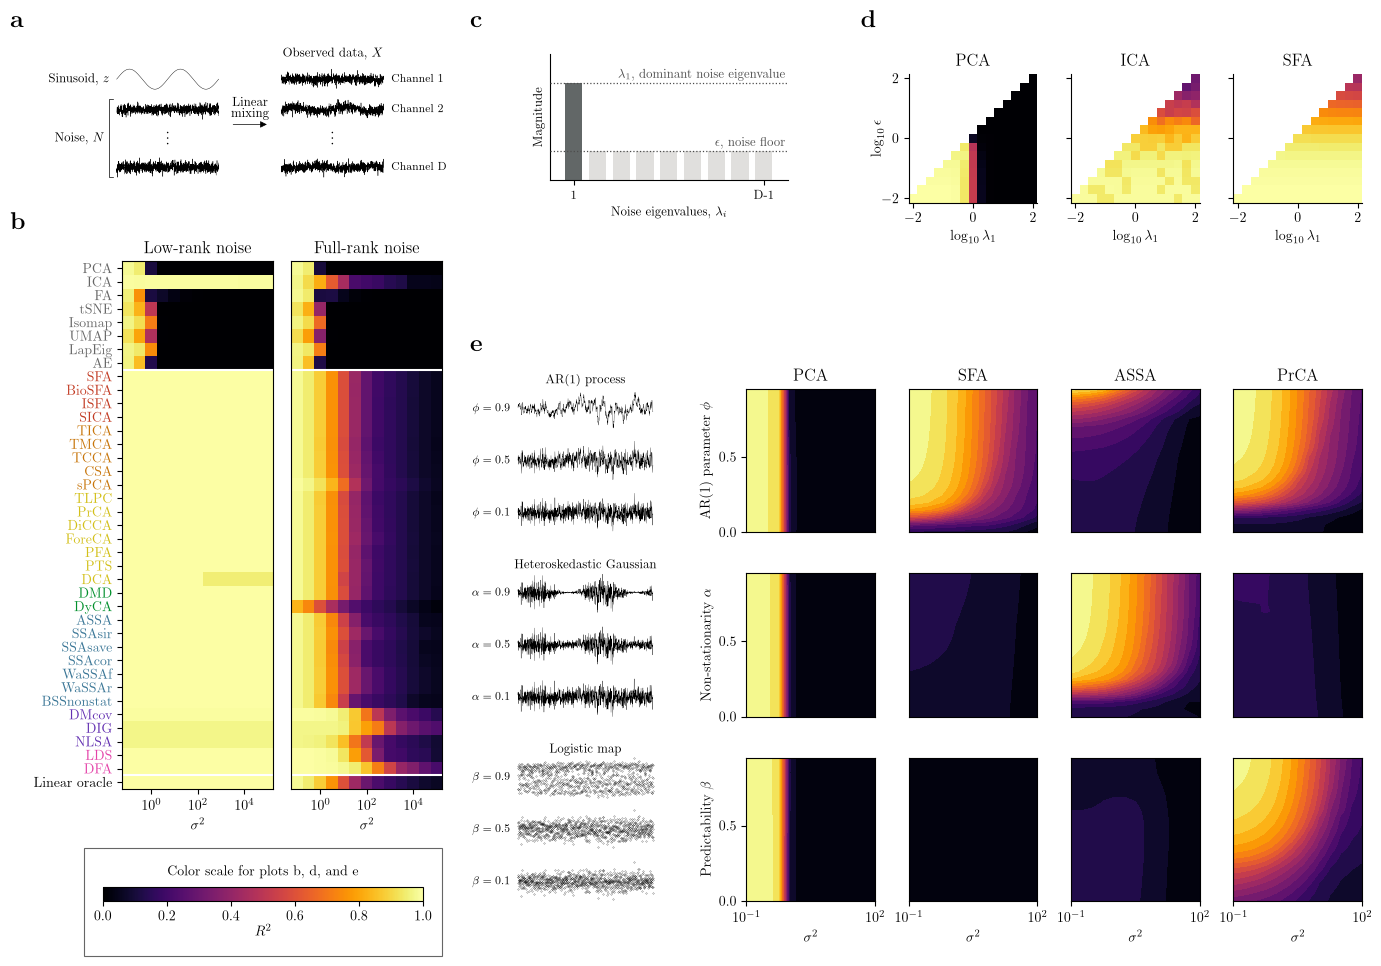

In [11]:
def main_figure(noise_results, spectrum_results, process_results,
                spectrum_examples=('PCA', 'ICA', 'SFA')):
    fig = plt.figure(figsize=(16, 11))
    outer = fig.add_gridspec(1, 2, width_ratios=[2.2, 5.8], wspace=0.13)

    # left: generative-model schematic, then the noise-variance heatmaps and colour bar
    # (the empty rows leave space for the heatmap titles and x labels)
    left = outer[0].subgridspec(5, 2, height_ratios=[0.62, 0.22, 2.6, 0.3, 0.07],
                                hspace=0.12, wspace=0.12)
    ax_model = fig.add_subplot(left[0, :])
    box = ax_model.get_position()  # widen the schematic to the left, over the method names
    ax_model.set_position([box.x0 - 0.045, box.y0, box.width + 0.045, box.height])
    ax_low, ax_full = fig.add_subplot(left[2, 0]), fig.add_subplot(left[2, 1])
    ax_cbar = fig.add_subplot(left[4, :])

    # right: a column of example signals, a spacer for the y labels, and four method columns;
    # the spectrum schematic sits over the first two columns and the spectrum heatmaps over the
    # last three, above the grid of signal processes
    right = outer[1].subgridspec(5, 6, height_ratios=[1, 0.5, 0.85, 0.85, 0.85],
                                 width_ratios=[1.05, 0.2, 1, 1, 1, 1], hspace=0.3, wspace=0.3)
    ax_spectrum = fig.add_subplot(right[0, 0:3])
    box = ax_spectrum.get_position()  # a smaller schematic, top-aligned with the heatmaps
    width, height = 0.75 * (box.width - 0.025), 0.75 * box.height
    ax_spectrum.set_position([box.x0 + 0.02, box.y1 - height, width, height])
    ax_examples = [fig.add_subplot(right[0, c]) for c in (3, 4, 5)]
    ax_traces = [fig.add_subplot(right[r, 0]) for r in (2, 3, 4)]
    ax_grid = [[fig.add_subplot(right[r, c]) for c in (2, 3, 4, 5)] for r in (2, 3, 4)]

    # a: generative model
    plot_generative_schematic(ax_model)

    # b: noise-variance experiment
    plot_noise_heatmap(ax_low, noise_results, 'low-rank', aspect='auto')
    im = plot_noise_heatmap(ax_full, noise_results, 'full-rank', show_names=False,
                            aspect='auto')

    # colour bar shared by all heatmaps and contour plots, in a box
    fig.colorbar(im, cax=ax_cbar, orientation='horizontal').set_label(r'$R^2$', labelpad=1)
    pad_x, pad_top, pad_bottom = 0.012, 0.035, 0.05
    box = ax_cbar.get_position()  # shift left so the box ends at the right edge of the heatmaps
    shift = box.x1 + pad_x - ax_full.get_position().x1
    ax_cbar.set_position([box.x0 - shift, box.y0, box.width, box.height])
    box = ax_cbar.get_position()
    fig.text((box.x0 + box.x1) / 2, box.y1 + 0.008, 'Color scale for plots b, d, and e',
             ha='center', va='bottom', fontsize=10)
    fig.add_artist(mpl.patches.Rectangle(
        (box.x0 - pad_x, box.y0 - pad_bottom), box.width + 2 * pad_x,
        box.height + pad_top + pad_bottom, transform=fig.transFigure,
        fill=False, edgecolor='0.4', linewidth=0.8))

    # c-d: noise-spectrum experiment
    plot_spectrum_schematic(ax_spectrum)
    for i, (ax, name) in enumerate(zip(ax_examples, spectrum_examples)):
        plot_spectrum_heatmap(ax, spectrum_results, name, show_ylabel=(i == 0))

    # e: signal processes (rows) for each method (columns)
    rows = [('ar1', r'\phi', r'AR(1) parameter $\phi$', 'AR(1) process'),
            ('heteroskedastic', r'\alpha', r'Non-stationarity $\alpha$', 'Heteroskedastic Gaussian'),
            ('logistic', r'\beta', r'Predictability $\beta$', 'Logistic map')]
    for r, (process, symbol, ylabel, title) in enumerate(rows):
        plot_example_signals(ax_traces[r], process, symbol, title)
        results = process_results[process]
        for c, (ax, name) in enumerate(zip(ax_grid[r], results['methods'])):
            plot_process_contour(ax, results, name)
            if r == 0:
                ax.set_title(name)
            if r < len(rows) - 1:
                ax.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
            else:
                ax.set_xlabel(r'$\sigma^2$')
            if c == 0:
                ax.set_yticks([0, 0.5])
                ax.set_ylabel(ylabel)
            else:
                ax.set_yticks([])
            ax.set_ylim(results['params'][0], results['params'][-1])

    # panel labels: a and b aligned on the left, and a, c and d aligned along the top
    y_top = ax_model.get_position().y1 + 0.02
    x_left = ax_low.get_position().x0 - 0.07
    label_panel(fig, [ax_model], 'a', x=x_left, y=y_top)
    label_panel(fig, [ax_low], 'b', x=x_left, y_offset=0.025)
    label_panel(fig, [ax_spectrum], 'c', x_offset=-0.05, y=y_top)
    label_panel(fig, ax_examples, 'd', x_offset=-0.03, y=y_top)
    label_panel(fig, ax_traces, 'e', x_offset=-0.03, y_offset=0.03)
    return fig


fig = main_figure(noise_results, spectrum_results, process_results)
fig.savefig(FIGURES_DIR / 'figure_lam1_eps.pdf', dpi=500, bbox_inches='tight')
plt.show()

## S1. Noise robustness at extreme noise variances

Experiment 1 with low-rank noise only, extended to noise variances every decade from $\sigma^2 = 10^{-2}$ to $10^{14}$. Low-rank noise leaves the signal exactly linearly recoverable at any noise variance, so this shows how far each method's robustness extends before numerical precision limits it.

Loading results/noise_extreme.npz


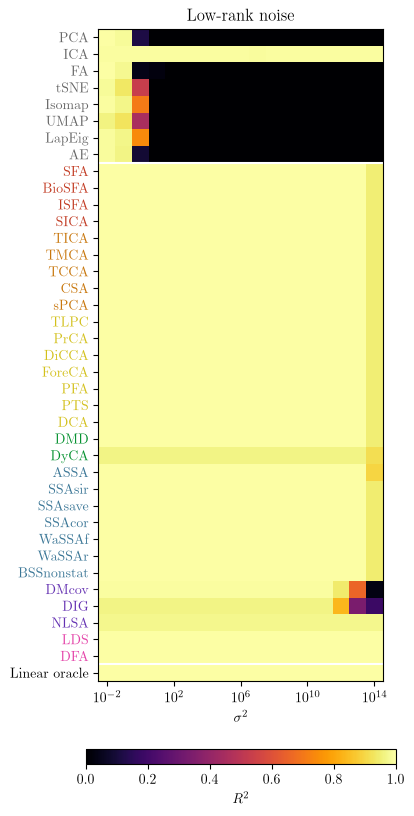

In [12]:
N_ITERS_EXTREME = setting(20, 2)
EXTREME_VARIANCES = 10.0 ** np.arange(-2, 15, 1)  # every decade, 10^-2, 10^-1, ..., 10^14


def extreme_noise_iteration(seed, variances):
    # as noise_iteration, for low-rank noise only
    rng = np.random.default_rng(seed)
    A, Q, W = random_mixing(rng)
    R2 = np.zeros((len(variances), 1, len(METHOD_NAMES)))
    failures = []
    for i, variance in enumerate(variances):
        noise_eigvals = np.full(D - 1, variance)
        noise_eigvals[-1] = 0.0
        X = observe(Z, noise_eigvals, A, Q, W)
        for k, name in enumerate(METHOD_NAMES):
            R2[i, 0, k] = safe_score(name, X, Z, failures=failures)
    return R2, failures


extreme_results = load_or_run('noise_extreme', lambda: {
    'R2': run_iterations(extreme_noise_iteration, N_ITERS_EXTREME, experiment_id=8,
                         variances=EXTREME_VARIANCES),  # (iteration, noise variance, 1, method)
    'noise_variances': EXTREME_VARIANCES, 'noise_types': ['low-rank'], 'methods': METHOD_NAMES})

fig, ax = plt.subplots(figsize=(5, 11))
im = plot_noise_heatmap(ax, extreme_results, 'low-rank')
ax.set_aspect(1)
log_ticks(ax, extreme_results['noise_variances'], powers=(-2, 2, 6, 10, 14))
fig.colorbar(im, ax=ax, orientation='horizontal', shrink=0.8, pad=0.08).set_label(r'$R^2$')
fig.savefig(FIGURES_DIR / 'figure_extreme_noise.pdf', dpi=500, bbox_inches='tight')
plt.show()

## S2. Noise spectrum for all methods

Mean $R^2$ over the $(\lambda_1, \epsilon)$ grid of experiment 2 for every method, as in panel d of the main figure (no new runs).

/var/folders/yv/kz_y7xwx1_92cdnpc1qqw46h0000gn/T/ipykernel_18774/3479236129.py:128: RuntimeWarning: Mean of empty slice
  R2 = np.nanmean(results['R2'], axis=0)[:, :, list(results['methods']).index(name)]


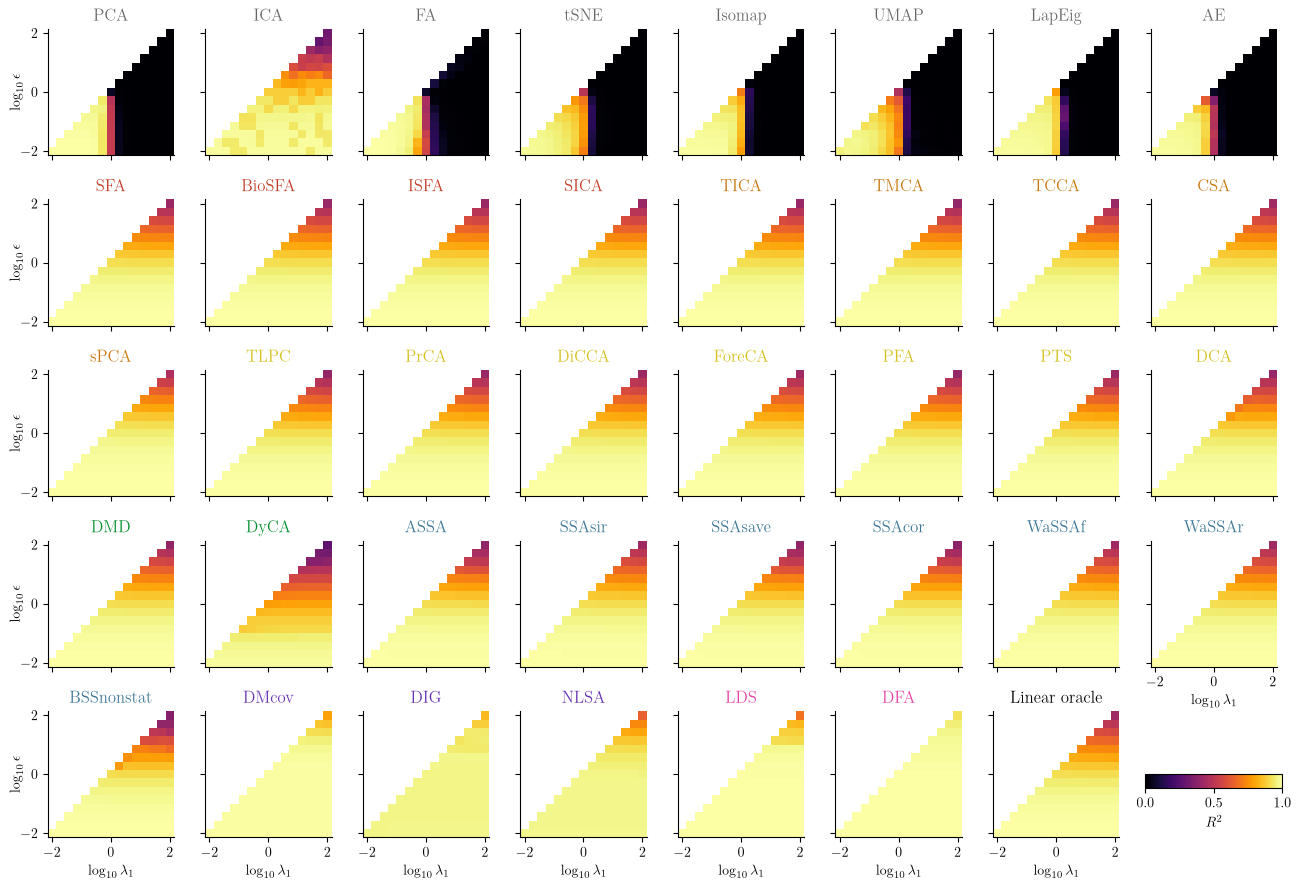

In [13]:
def spectrum_all_figure(results, n_cols=8):
    # mean R2 over the (lambda1, epsilon) grid for every method (as in panel d of the
    # main figure), in the order of the method list, with the colour bar in the last panel
    names = list(results['methods'])
    n_rows = int(np.ceil((len(names) + 1) / n_cols))
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(2 * n_cols, 2.1 * n_rows))
    for i, (ax, name) in enumerate(zip(axs.flat, names)):
        plot_spectrum_heatmap(ax, results, name, show_ylabel=(i % n_cols == 0))
        ax.title.set_color(colour(name))
        ax.title.set_fontweight('bold')
        if i < len(names) - n_cols:  # x labels on the lowest panel of each column only
            ax.set_xlabel('')
            ax.tick_params(labelbottom=False)

    # colour bar in the first unused panel, and the remaining panels hidden
    unused = axs.flat[len(names):]
    for ax in unused:
        ax.axis('off')
    im = axs.flat[0].collections[0]
    cbar = fig.colorbar(im, ax=unused[0], orientation='horizontal', fraction=0.5, aspect=10)
    cbar.set_label(r'$R^2$')
    fig.subplots_adjust(hspace=0.35, wspace=0.15)
    return fig


fig = spectrum_all_figure(spectrum_results)
fig.savefig(FIGURES_DIR / 'figure_spectrum_all.pdf', dpi=500, bbox_inches='tight')
plt.show()

## S3. Best of three components

Experiment 1, with each method extracting three components (a three-unit bottleneck for the autoencoder) and scored by the component that best recovers the signal. This shows whether a method that fails in experiment 1 finds the signal in a less dominant component.

Loading results/noise_best_of_three.npz


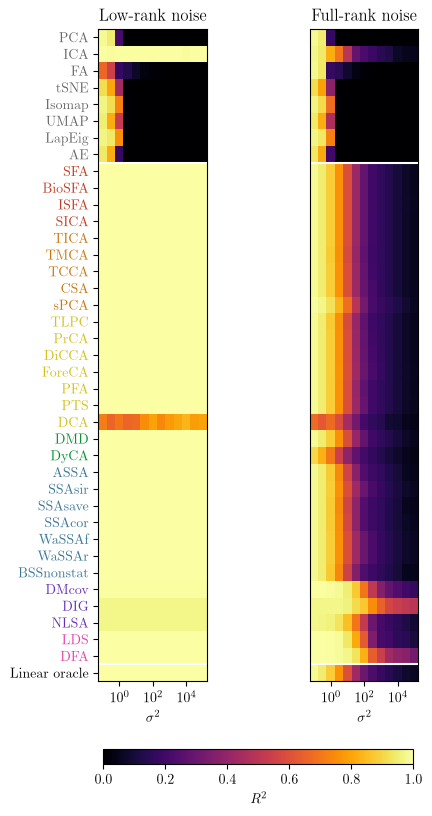

In [14]:
best_of_three_results = load_or_run('noise_best_of_three',
                                    lambda: run_noise_experiment(n_components=3, experiment_id=1))

fig, axs = plt.subplots(1, 2, figsize=(5, 11))
plot_noise_heatmap(axs[0], best_of_three_results, 'low-rank')
im = plot_noise_heatmap(axs[1], best_of_three_results, 'full-rank', show_names=False)
fig.colorbar(im, ax=axs, orientation='horizontal', shrink=0.8, pad=0.08).set_label(r'$R^2$')
fig.savefig(FIGURES_DIR / 'figure_best_of_three.pdf', dpi=500, bbox_inches='tight')
plt.show()